# Combining the probes

Runs every way of combining the Hindi and Marathi probes for each Marathi budget
in `config.yaml` (25 to 800 labelled sentences), with five seeds, at the main
setting (layer 7, first-piece). It follows the protocol in the readme. Scores
are on Marathi dev; the test split stays untouched.

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import numpy as np
import torch
import yaml
from sklearn.linear_model import LogisticRegression

ROOT = Path.cwd()
CONFIG = yaml.safe_load((ROOT / "config.yaml").read_text())
CACHE = ROOT / "data" / "cache"
samples = json.loads((CACHE / "samples.json").read_text())
LAYER, POOLING = CONFIG["main_setting"]["layer"], CONFIG["main_setting"]["pooling"]


class Split:
    """One split's cached features at the main setting, its labels (True = Nom) and its nouns by sentence."""

    def __init__(self, language: str, split: str):
        nouns = json.loads((CACHE / f"{language}_{split}_nouns.json").read_text())
        self.x = np.asarray(np.load(CACHE / f"{language}_{split}_{POOLING}.npy", mmap_mode="r")[LAYER])
        self.y = np.array([noun["label"] == "Nom" for noun in nouns])
        self.by_sentence = defaultdict(list)
        for k, noun in enumerate(nouns):
            self.by_sentence[noun["sentence"]].append(k)

    def rows(self, sentences) -> tuple[np.ndarray, np.ndarray]:
        """Features and labels of the nouns in these sentences; a sentence listed twice is used twice."""
        keep = [k for s in sentences for k in self.by_sentence[s]]
        return self.x[keep], self.y[keep]


hindi, marathi, dev = Split("hi", "train"), Split("mr", "train"), Split("mr", "dev")
majority = max(dev.y.mean(), 1 - dev.y.mean())
print(f"layer {LAYER}, {POOLING}-piece; Marathi dev: {len(dev.y)} nouns, majority {majority:.3f}")

layer 7, first-piece; Marathi dev: 3308 nouns, majority 0.516


## Methods

With a budget of n labelled Marathi sentences:

- **Hindi probe:** trained on the seed's 800 Hindi sentences only.
- **Marathi probe:** trained on 80% of the n sentences, and again on all n.
- **Pooled:** one probe trained on the Hindi sentences plus all n Marathi sentences.
- **Weight blend:** the Hindi and Marathi (80%) probes, each scaled to length 1,
  mixed in one fixed proportion for every noun. The proportion and a shared
  scale and bias are learned on the other 20%.
- **Router:** the same, but the proportion depends on the noun through a gate
  learned on the 20%. How strongly the gate is held back (its penalty) is chosen
  by cross-validation over the 20%'s sentences; "no gate" is one of the choices,
  so the router can fall back to the weight blend.
- **Marathi + Marathi control:** the blend and the router again, with the Hindi
  probe swapped for a second Marathi probe trained on a resample of the same 80%.
  It uses no extra data, so it shows what combining two probes gives on its own.

The weight blend is exactly the router with a gate that ignores the noun, so any
difference between them comes from choosing per noun.

In [2]:
PENALTIES = [None, 1e4, 1e3, 1e2, 1e1, 1.0, 0.1, 0.01]


def probe(x: np.ndarray, y: np.ndarray) -> LogisticRegression:
    return LogisticRegression(max_iter=5000).fit(x, y)


def unit(model: LogisticRegression) -> np.ndarray:
    w = model.coef_[0]
    return w / np.linalg.norm(w)


def logits(mix, x, s_a, s_b) -> np.ndarray:
    """a·(g·s_a + (1 − g)·s_b) + b, with gate g = sigmoid(v·h + c)."""
    c, a, b, v = mix
    g = 1 / (1 + np.exp(-(x @ v + c)))
    return a * (g * s_a + (1 - g) * s_b) + b


def fit_mix(x, s_a, s_b, y, penalty=None, start=(0.0, 1.0, 0.0)):
    """Learn (c, a, b, v) of `logits` from two probes' scores s_a and s_b.

    With penalty None, v stays 0 and every noun gets the same mix (the weight
    blend); otherwise v is learned with an L2 penalty of that strength (the
    router). Like scikit-learn's C=1, the loss is the summed log loss plus a²/2.
    """
    x, s_a, s_b, y = (torch.as_tensor(t, dtype=torch.float64) for t in (x, s_a, s_b, y))
    c, a, b = (torch.tensor(float(t), dtype=torch.float64, requires_grad=True) for t in start)
    v = torch.zeros(x.shape[1], dtype=torch.float64, requires_grad=penalty is not None)
    optimiser = torch.optim.LBFGS([c, a, b] + ([v] if penalty is not None else []),
                                  max_iter=500, line_search_fn="strong_wolfe")

    def closure():
        optimiser.zero_grad()
        g = torch.sigmoid(x @ v + c)
        out = a * (g * s_a + (1 - g) * s_b) + b
        loss = torch.nn.functional.binary_cross_entropy_with_logits(out, y, reduction="sum") + a * a / 2
        if penalty is not None:
            loss = loss + penalty * (v @ v) / 2
        loss.backward()
        return loss

    optimiser.step(closure)
    return c.item(), a.item(), b.item(), v.detach().numpy()


def combine(w_a: np.ndarray, w_b: np.ndarray, sentences: list[int]):
    """Fit the weight blend and the router of two length-1 probes on these Marathi sentences."""
    x, y = marathi.rows(sentences)
    k = min(5, len(sentences))
    fold = np.concatenate([[i % k] * len(marathi.by_sentence[s]) for i, s in enumerate(sentences)])
    s_a, s_b = x @ w_a, x @ w_b
    blend = fit_mix(x, s_a, s_b, y)

    def held_out_loss(penalty):
        loss = 0.0
        for f in range(k):
            train, test = fold != f, fold == f
            mix = fit_mix(x[train], s_a[train], s_b[train], y[train], penalty, blend[:3])
            z = logits(mix, x[test], s_a[test], s_b[test])
            loss += np.logaddexp(0, -np.where(y[test], z, -z)).sum()
        return loss

    penalty = min(PENALTIES, key=held_out_loss)
    router = blend if penalty is None else fit_mix(x, s_a, s_b, y, penalty, blend[:3])
    return blend, router, penalty

## Sweep

For each seed, the Marathi budget is the first n sentences of the seed's
Marathi order, so smaller budgets sit inside larger ones. The first 80% of the
budget trains the Marathi probes; the last 20% is held out for the blend and
the router. Takes a few minutes.

In [3]:
share = CONFIG["router_share"]
runs = []
for seed in map(str, CONFIG["seeds"]):
    rng = np.random.default_rng(int(seed))
    hindi_x, hindi_y = hindi.rows(samples["hi"][seed])
    hindi_probe = probe(hindi_x, hindi_y)
    for n in CONFIG["marathi_train_sentences"]:
        budget = samples["mr"][seed][:n]
        cut = round(n * (1 - share))
        probe_part, router_part = budget[:cut], budget[cut:]
        marathi_probe = probe(*marathi.rows(probe_part))
        resampled_probe = probe(*marathi.rows(rng.choice(probe_part, len(probe_part))))
        marathi_x, marathi_y = marathi.rows(budget)
        run = {
            "seed": int(seed), "n": n,
            "hindi": hindi_probe.score(dev.x, dev.y),
            "marathi_80": marathi_probe.score(dev.x, dev.y),
            "marathi_100": probe(marathi_x, marathi_y).score(dev.x, dev.y),
            "pooled": probe(np.vstack([hindi_x, marathi_x]), np.concatenate([hindi_y, marathi_y])).score(dev.x, dev.y),
        }
        for name, other in [("hm", hindi_probe), ("mm", resampled_probe)]:
            w_a, w_b = unit(other), unit(marathi_probe)
            blend, router, penalty = combine(w_a, w_b, router_part)
            s_a, s_b = dev.x @ w_a, dev.x @ w_b
            run[f"blend_{name}"] = np.mean((logits(blend, dev.x, s_a, s_b) > 0) == dev.y)
            run[f"router_{name}"] = np.mean((logits(router, dev.x, s_a, s_b) > 0) == dev.y)
            run[f"other_share_{name}"] = 1 / (1 + np.exp(-blend[0]))
            run[f"penalty_{name}"] = penalty
        runs.append(run)
        print(f"seed {seed}, n {n:3d}: " + ", ".join(
            f"{key} {run[key]:.3f}" for key in ["marathi_100", "pooled", "blend_hm", "router_hm"]), flush=True)

seed 13, n  25: marathi_100 0.812, pooled 0.849, blend_hm 0.862, router_hm 0.852


seed 13, n  50: marathi_100 0.831, pooled 0.849, blend_hm 0.835, router_hm 0.826


seed 13, n 100: marathi_100 0.833, pooled 0.844, blend_hm 0.871, router_hm 0.873


seed 13, n 200: marathi_100 0.847, pooled 0.852, blend_hm 0.871, router_hm 0.871


seed 13, n 400: marathi_100 0.853, pooled 0.866, blend_hm 0.876, router_hm 0.878


seed 13, n 800: marathi_100 0.859, pooled 0.880, blend_hm 0.891, router_hm 0.891


... (20 outputs left out)

seed 89, n 100: marathi_100 0.840, pooled 0.859, blend_hm 0.864, router_hm 0.865


seed 89, n 200: marathi_100 0.851, pooled 0.864, blend_hm 0.878, router_hm 0.877


seed 89, n 400: marathi_100 0.877, pooled 0.869, blend_hm 0.888, router_hm 0.890


seed 89, n 800: marathi_100 0.874, pooled 0.888, blend_hm 0.901, router_hm 0.903


## Results

Mean ± standard deviation over the five seeds. `other share` is the part of the
blend given to the Hindi probe (or to the second Marathi probe in the control).

n                                        25             50            100            200            400            800
Hindi probe                     0.839 ±0.007    0.839 ±0.007    0.839 ±0.007    0.839 ±0.007    0.839 ±0.007    0.839 ±0.007
Marathi probe, 80%              0.732 ±0.008    0.800 ±0.013    0.839 ±0.006    0.853 ±0.013    0.869 ±0.011    0.871 ±0.009
Marathi probe, all n            0.758 ±0.031    0.814 ±0.010    0.847 ±0.009    0.861 ±0.011    0.871 ±0.010    0.871 ±0.006
Pooled data                     0.843 ±0.007    0.843 ±0.007    0.849 ±0.007    0.859 ±0.005    0.869 ±0.006    0.884 ±0.005
Blend, Hindi + Marathi          0.803 ±0.062    0.831 ±0.004    0.865 ±0.005    0.876 ±0.008    0.887 ±0.006    0.895 ±0.005
Router, Hindi + Marathi         0.796 ±0.054    0.825 ±0.008    0.867 ±0.003    0.876 ±0.008    0.889 ±0.006    0.895 ±0.005
Blend, Marathi + Marathi        0.718 ±0.056    0.790 ±0.011    0.841 ±0.003    0.854 ±0.014    0.874 ±0.006    0.875 ±0.008
Router

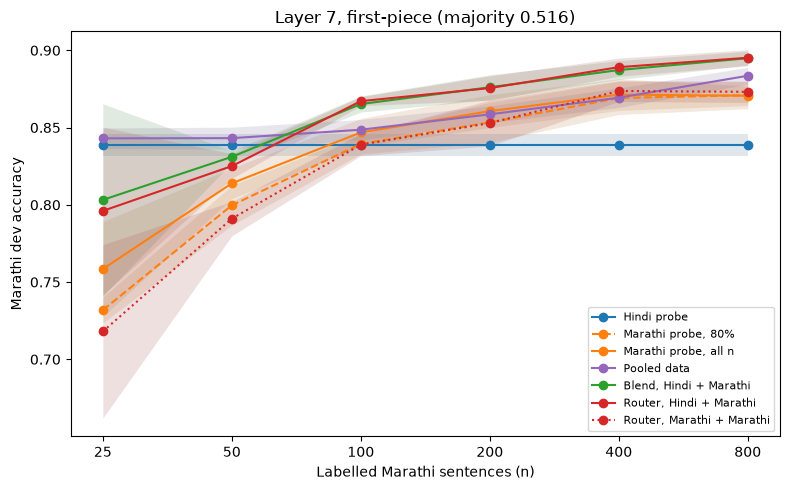

In [4]:
methods = {
    "hindi": "Hindi probe",
    "marathi_80": "Marathi probe, 80%",
    "marathi_100": "Marathi probe, all n",
    "pooled": "Pooled data",
    "blend_hm": "Blend, Hindi + Marathi",
    "router_hm": "Router, Hindi + Marathi",
    "blend_mm": "Blend, Marathi + Marathi",
    "router_mm": "Router, Marathi + Marathi",
    "other_share_hm": "Hindi share of blend",
    "other_share_mm": "2nd Marathi share of blend",
}
sizes = CONFIG["marathi_train_sentences"]
summary = {key: {n: {"mean": np.mean([r[key] for r in runs if r["n"] == n]),
                     "std": np.std([r[key] for r in runs if r["n"] == n])} for n in sizes}
           for key in methods}
result = {"layer": LAYER, "pooling": POOLING, "split": "mr dev", "majority": majority,
          "summary": summary, "runs": runs}
(ROOT / "results" / "combination.json").write_text(json.dumps(result, indent=2) + "\n")

print(f"{'n':28s}" + "".join(f"{n:>15d}" for n in sizes))
for key, label in methods.items():
    print(f"{label:28s}" + "".join(f"{summary[key][n]['mean']:9.3f} ±{summary[key][n]['std']:.3f}" for n in sizes))
print("\nRouter penalty chosen (None = fell back to the blend):")
for name in ["hm", "mm"]:
    print(f"  {name}:", {n: [r[f"penalty_{name}"] for r in runs if r["n"] == n] for n in sizes})

figure, ax = plt.subplots(figsize=(8, 5))
lines = [("hindi", "C0", "-"), ("marathi_80", "C1", "--"), ("marathi_100", "C1", "-"),
         ("pooled", "C4", "-"), ("blend_hm", "C2", "-"), ("router_hm", "C3", "-"), ("router_mm", "C3", ":")]
for key, color, style in lines:
    mean = np.array([summary[key][n]["mean"] for n in sizes])
    std = np.array([summary[key][n]["std"] for n in sizes])
    # The band is the line's colour mixed half-way with grey.
    band = 0.5 * np.array(to_rgb(color)) + 0.5 * np.array(to_rgb("grey"))
    ax.fill_between(sizes, mean - std, mean + std, color=band, alpha=0.18, linewidth=0)
    ax.plot(sizes, mean, color=color, linestyle=style, marker="o", label=methods[key])
ax.set(xscale="log", xticks=sizes, xticklabels=sizes, xlabel="Labelled Marathi sentences (n)",
       ylabel="Marathi dev accuracy", title=f"Layer {LAYER}, {POOLING}-piece (majority {majority:.3f})")
ax.minorticks_off()
ax.legend(fontsize=8)
figure.tight_layout()
figure.savefig(ROOT / "results" / "combination.png", dpi=150)
plt.show()